In [2]:
import kagglehub
path = kagglehub.dataset_download("fedesoriano/heart-failure-prediction")

Using Colab cache for faster access to the 'heart-failure-prediction' dataset.


In [3]:
import os
os.listdir(path)

['heart.csv']

In [4]:
import pandas as pd
df=pd.read_csv(path+'/heart.csv')

In [5]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [6]:
df.shape

(918, 12)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [8]:
for i in df.columns:
  print(f'Column {i} has {df[i].isnull().sum()} : {df[i].isnull().mean()*100:.4f}% missing values.')

Column Age has 0 : 0.0000% missing values.
Column Sex has 0 : 0.0000% missing values.
Column ChestPainType has 0 : 0.0000% missing values.
Column RestingBP has 0 : 0.0000% missing values.
Column Cholesterol has 0 : 0.0000% missing values.
Column FastingBS has 0 : 0.0000% missing values.
Column RestingECG has 0 : 0.0000% missing values.
Column MaxHR has 0 : 0.0000% missing values.
Column ExerciseAngina has 0 : 0.0000% missing values.
Column Oldpeak has 0 : 0.0000% missing values.
Column ST_Slope has 0 : 0.0000% missing values.
Column HeartDisease has 0 : 0.0000% missing values.


In [9]:
df.duplicated().sum()

np.int64(0)

## There are no nulls and duplicates in the dataset.

In [10]:
categorical=[i for i in df.columns if df[i].dtype=="O"]
numerical=[i for i in df.columns if i not in categorical]

In [11]:
print("Categorical columns are :",categorical)
print("Numerical columns are :",numerical)

Categorical columns are : ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
Numerical columns are : ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak', 'HeartDisease']


In [12]:
for i in categorical:
  print(f"Column {i} Has {len(df[i].unique())} values")

Column Sex Has 2 values
Column ChestPainType Has 4 values
Column RestingECG Has 3 values
Column ExerciseAngina Has 2 values
Column ST_Slope Has 3 values


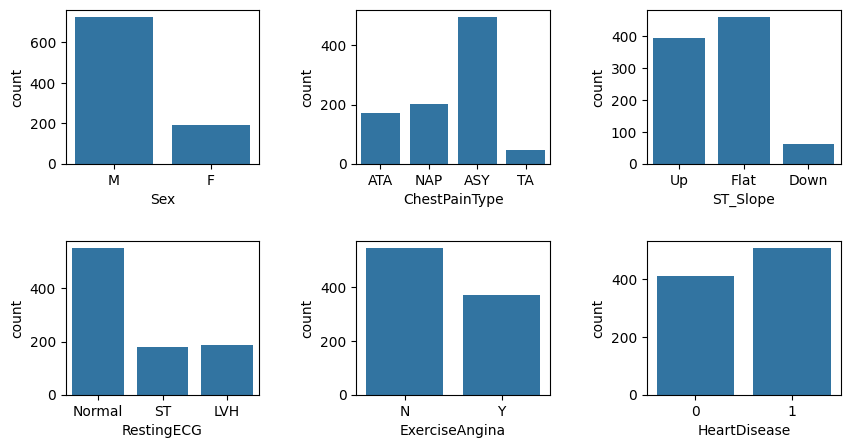

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
fig,ax=plt.subplots(2,3,figsize=(10,5))
sns.countplot(df,x='Sex',ax=ax[0,0])
sns.countplot(df,x='ChestPainType',ax=ax[0,1])
sns.countplot(df,x='RestingECG',ax=ax[1,0])
sns.countplot(df,x='ExerciseAngina',ax=ax[1,1])
sns.countplot(df,x='ST_Slope',ax=ax[0,2])
sns.countplot(df,x='HeartDisease',ax=ax[1,2])
plt.subplots_adjust(wspace=0.5,hspace=0.5)
plt.show()

## This dataset is more biased towards males.
## ASY ( Atypical Angina ) type of chestpain is coming out for most of the patients.
## Flat the slope of the peak exercise ST segment is dominating among [Up: upsloping, Flat: flat, Down: downsloping]
## RestingECG is coming out to be normal in most of the cases.
## Exercise Induced Angina is not preferred by most of the individuals.
## 1: heart disease, 0: Normal
## Many peoples are suffering from heart disease.

In [14]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


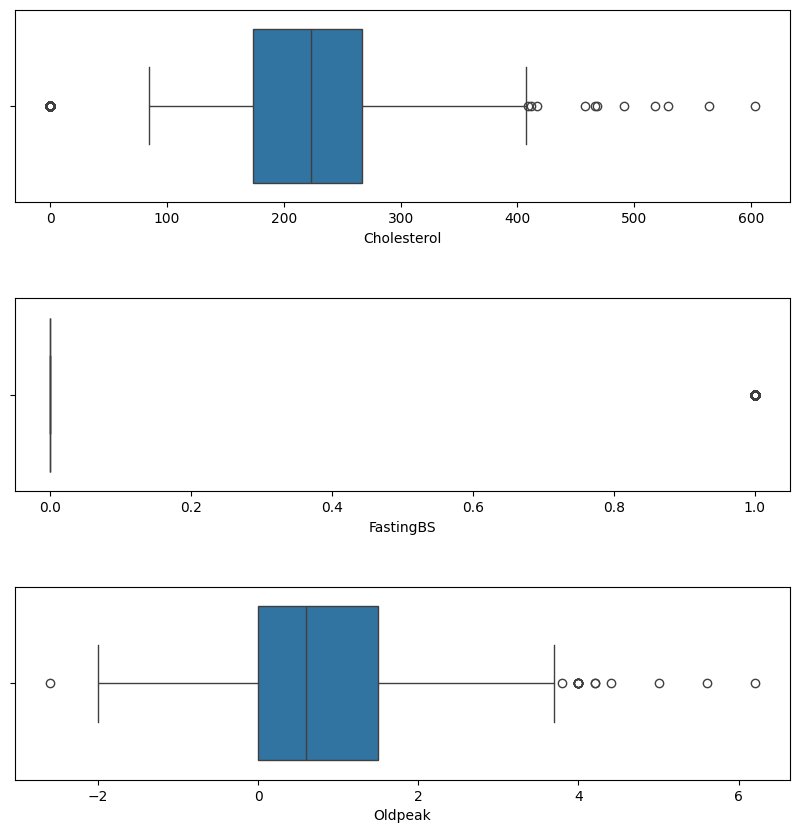

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
fig,ax=plt.subplots(3,1,figsize=(10,10))
sns.boxplot(df,x='Cholesterol',ax=ax[0])
sns.boxplot(df,x='FastingBS',ax=ax[1])
sns.boxplot(df,x='Oldpeak',ax=ax[2])
plt.subplots_adjust(hspace=0.5)
plt.show()

In [16]:
df=df[(df['Oldpeak']>-2) & (df['Oldpeak']<6)]

In [17]:
df['FastingBS'].unique()

array([0, 1])

## FastingBS can be considered as a categorical column

In [18]:
print(categorical)
print(numerical)

['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak', 'HeartDisease']


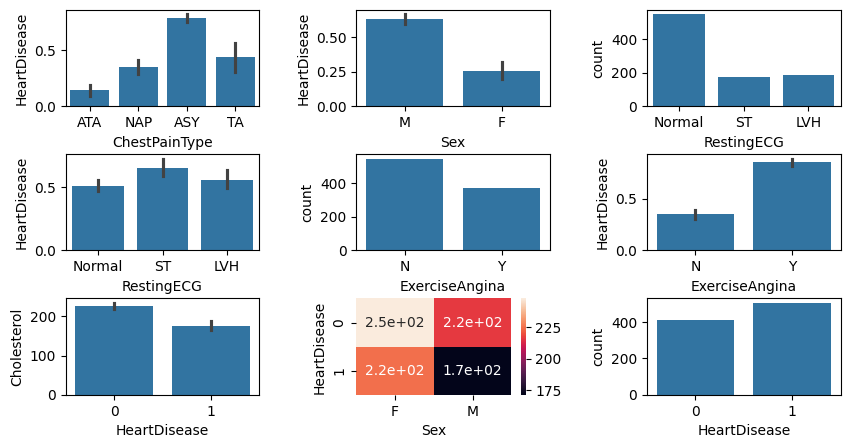

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
fig,ax=plt.subplots(3,3,figsize=(10,5))
sns.barplot(df,x='ChestPainType',y='HeartDisease',ax=ax[0,0])
sns.barplot(df,x='Sex',y='HeartDisease',ax=ax[0,1])
sns.countplot(df,x='RestingECG',ax=ax[0,2])
sns.barplot(df,x='RestingECG',y='HeartDisease',ax=ax[1,0])
sns.countplot(df,x='ExerciseAngina',ax=ax[1,1])
sns.barplot(df,x='ExerciseAngina',y='HeartDisease',ax=ax[1,2])
sns.barplot(df,y='Cholesterol',x='HeartDisease',ax=ax[2,0])
table1=pd.pivot_table(df,index='HeartDisease',columns='Sex',values='Cholesterol',aggfunc='mean')
sns.heatmap(table1,ax=ax[2,1],annot=True)
sns.countplot(df,x='HeartDisease',ax=ax[2,2])
plt.subplots_adjust(wspace=0.5,hspace=0.5)
plt.show()

## Patients having ASY type of ChestPain have more chances to get Heart Disease.
## As the dataset is Male Bias so we can't comment that males have more chances to heart disease.
## Most of the people have normal RestingECG and quite safe to Heart Disease as compared to those who have ST or LVH RestingECG.
## The problem of Exercise Angina is happening to less number of people as per the data points but these people who suffer from it are more prone towards Heart Disease.
## People who have heart disease have cholesterol lvl around 150-170 and individuals without disease has a higher cholesterol level.
## Females with cholesterol lvl around 250 are not having heart disease and males around 220. On the other hand, Females at this level of 220 are suffering from disease. Also males with level 170 are suffering from this disease.

In [20]:
for i in categorical:
  print(f"Unique values for {i} : {df[i].unique()}")

Unique values for Sex : ['M' 'F']
Unique values for ChestPainType : ['ATA' 'NAP' 'ASY' 'TA']
Unique values for RestingECG : ['Normal' 'ST' 'LVH']
Unique values for ExerciseAngina : ['N' 'Y']
Unique values for ST_Slope : ['Up' 'Flat' 'Down']


In [21]:
x=df.drop(columns=['HeartDisease'])
y=df['HeartDisease']

In [22]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [23]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [24]:
from sklearn.preprocessing import OneHotEncoder,StandardScaler,LabelEncoder
ohe=OneHotEncoder(sparse_output=False,drop='first')
le=LabelEncoder()
scaler=StandardScaler()

In [25]:
le.fit(x['Sex'])
x_train['Sex']=le.transform(x_train['Sex'])
x_test['Sex']=le.transform(x_test['Sex'])

In [26]:
import joblib
with open('label_encoder.pkl','wb') as f:
  joblib.dump(le,f)

In [27]:
ohe.fit(df[['ChestPainType','RestingECG','ST_Slope','ExerciseAngina']])
features=ohe.transform(x_train[['ChestPainType','RestingECG','ST_Slope','ExerciseAngina']])
features=pd.DataFrame(features,columns=ohe.get_feature_names_out(),index=x_train.index)
x_train=pd.concat([x_train.drop(columns=['ChestPainType','RestingECG','ST_Slope','ExerciseAngina']),features],axis=1)
features=ohe.transform(x_test[['ChestPainType','RestingECG','ST_Slope','ExerciseAngina']])
features=pd.DataFrame(features,columns=ohe.get_feature_names_out(),index=x_test.index)
x_test=pd.concat([x_test.drop(columns=['ChestPainType','RestingECG','ST_Slope','ExerciseAngina']),features],axis=1)

In [28]:
x_train.reset_index(drop=True,inplace=True)
x_test.reset_index(drop=True,inplace=True)

In [29]:
with open('one_hot_encoder.pkl','wb') as f:
  joblib.dump(ohe,f)

In [30]:
x_train.head(2)

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ST_Slope_Flat,ST_Slope_Up,ExerciseAngina_Y
0,50,1,129,196,0,163,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
1,36,1,130,209,0,178,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0


In [31]:
x_train[['Age'	,'Sex','RestingBP',	'Cholesterol',	'FastingBS',	'MaxHR',	'Oldpeak']]=scaler.fit_transform(x_train[['Age'	,'Sex','RestingBP',	'Cholesterol',	'FastingBS',	'MaxHR',	'Oldpeak']])
x_test[['Age'	,'Sex','RestingBP',	'Cholesterol',	'FastingBS',	'MaxHR',	'Oldpeak']]=scaler.transform(x_test[['Age'	,'Sex','RestingBP',	'Cholesterol',	'FastingBS',	'MaxHR',	'Oldpeak']])

In [32]:
x_train.tail(2)

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ST_Slope_Flat,ST_Slope_Up,ExerciseAngina_Y
730,1.116065,0.535227,-0.680293,-1.895267,1.861025,-1.182679,1.047774,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
731,-1.465166,-1.868368,0.964273,1.772878,-0.537338,-0.240868,1.047774,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0


In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report,accuracy_score,confusion_matrix

In [34]:
models={
    'LogisticRegression':LogisticRegression(),
    'GaussianNB':GaussianNB(),
    'KNeighborsClassifier':KNeighborsClassifier(),
    'SVC':SVC()
}
accuracy={}
for i in range(len(list(models))):
  model=list(models.values())[i]
  model.fit(x_train,y_train)
  y_train_pred=model.predict(x_train)
  y_test_pred=model.predict(x_test)
  model_train_accuracy=accuracy_score(y_train,y_train_pred)
  model_test_accuracy=accuracy_score(y_test,y_test_pred)
  accuracy[list(models)[i]+'_train']=model_train_accuracy
  accuracy[list(models)[i]+'_test']=model_test_accuracy
  print(f"For {list(models)[i]} : ")
  print(f"Training Report : {classification_report(y_train,y_train_pred)}")
  print(f"Testing Report : {classification_report(y_test,y_test_pred)}\n")

For LogisticRegression : 
Training Report :               precision    recall  f1-score   support

           0       0.88      0.85      0.86       334
           1       0.88      0.90      0.89       398

    accuracy                           0.88       732
   macro avg       0.88      0.87      0.88       732
weighted avg       0.88      0.88      0.88       732

Testing Report :               precision    recall  f1-score   support

           0       0.81      0.86      0.83        76
           1       0.89      0.86      0.88       107

    accuracy                           0.86       183
   macro avg       0.85      0.86      0.85       183
weighted avg       0.86      0.86      0.86       183


For GaussianNB : 
Training Report :               precision    recall  f1-score   support

           0       0.86      0.84      0.85       334
           1       0.86      0.88      0.87       398

    accuracy                           0.86       732
   macro avg       0.86      0

In [35]:
pd.DataFrame(list(accuracy.values()),index=list(accuracy.keys()),columns=['Accuracy'])

,Accuracy
LogisticRegression_train,0.877049
LogisticRegression_test,0.857923
GaussianNB_train,0.860656
GaussianNB_test,0.846995
KNeighborsClassifier_train,0.911202
KNeighborsClassifier_test,0.857923
SVC_train,0.909836
SVC_test,0.874317


In [36]:
model=SVC()
model.fit(x_train,y_train)
y_train_pred=model.predict(x_train)
y_test_pred=model.predict(x_test)
print(f"Training Report : \n{confusion_matrix(y_train,y_train_pred)}")
print(f"Testing Report : \n{confusion_matrix(y_test,y_test_pred)}")

Training Report : 
[[292  42]
 [ 24 374]]
Testing Report : 
[[63 13]
 [10 97]]


In [37]:
with open('model.pkl','wb') as f:
  joblib.dump(model,f)